# Classification: House Style Typology

**Research Question:** Can machine learning algorithms accurately infer a residential property's architectural typology from its measurable spatial footprint, structural scale metrics and internal layout configuration alone, and which physical attributes serve as the most discriminative geometric boundaries between single-story, multi-story, one-and-a-half story and split-level residential typologies?

> Run `preprocessing.ipynb` first to generate `preprocessed_data.pkl`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from scipy.stats import uniform

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)
from sklearn.model_selection import cross_val_score, GridSearchCV, RandomizedSearchCV

## Data Loading

The preprocessed feature matrices and target labels produced by `preprocessing.ipynb` are loaded from disk. Class labels are label-encoded to integer indices, as required internally by XGBoost, while the original category names are retained separately for interpretable reporting.

In [2]:
from sklearn.preprocessing import LabelEncoder

with open('../data/processed/preprocessed_data.pkl', 'rb') as f:
    data = pickle.load(f)

X_clf            = data['X_clf']
X_train_clf      = data['X_train_clf']
X_test_clf       = data['X_test_clf']
preprocessor_clf = data['preprocessor_clf']

# Encode string class labels to integers.
# XGBoost 3.x stores integer class indices internally; working with strings
# causes a label-mismatch error when the same instance is re-fitted.
# The original names are preserved in class_labels for use in plots / reports.
_le         = LabelEncoder().fit(data['y_clf'])
class_labels = list(_le.classes_)
y_clf        = pd.Series(_le.transform(data['y_clf']),       index=data['y_clf'].index)
y_train_clf  = pd.Series(_le.transform(data['y_train_clf']), index=data['y_train_clf'].index)
y_test_clf   = pd.Series(_le.transform(data['y_test_clf']),  index=data['y_test_clf'].index)

print('Class mapping:')
for i, label in enumerate(class_labels):
    print(f'  {i} → {label}  (n={int((y_clf == i).sum())})')
print(f'\nX_train_clf : {X_train_clf.shape}  |  X_test_clf : {X_test_clf.shape}')

Class mapping:
  0 → 1.5-story  (n=333)
  1 → Multi-story  (n=905)
  2 → Single-story  (n=1481)
  3 → Split-level  (n=211)

X_train_clf : (2344, 30)  |  X_test_clf : (586, 30)


## Class Distribution

The distribution of the four typology classes is inspected prior to modelling, since class imbalance can bias accuracy-based comparisons and motivates the use of macro-averaged metrics throughout this notebook.

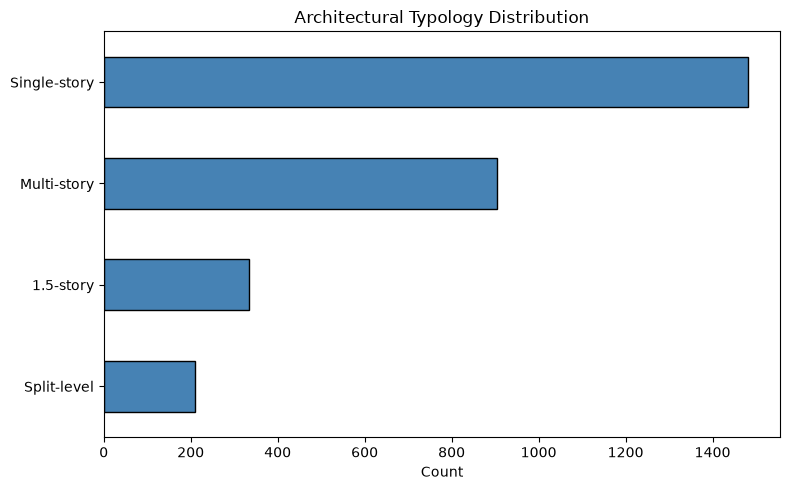

In [3]:
counts = y_clf.value_counts().sort_values()
counts.index = [class_labels[i] for i in counts.index]
plt.figure(figsize=(8, 5))
counts.plot(kind='barh', color='steelblue', edgecolor='black')
plt.title('Architectural Typology Distribution')
plt.xlabel('Count')
plt.tight_layout()
plt.show()

## Classifier Selection

Eight classifiers are compared under the same pipeline structure used for regression: a linear baseline (Logistic Regression), simple non-parametric methods (Decision Tree, KNN), ensemble approaches (Random Forest, Gradient Boosting, XGBoost), a margin-based method (SVC) and a small neural network (MLP). This gives a clear picture of which learning strategy handles the four-class typology problem best.

In [4]:
models = {
    'Logistic Regression':       LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree':             DecisionTreeClassifier(random_state=42),
    'Random Forest':             RandomForestClassifier(random_state=42),
    'Gradient Boosting':         GradientBoostingClassifier(random_state=42),
    'XGBoost':                   XGBClassifier(random_state=42,
                                               eval_metric='mlogloss', verbosity=0),
    'Support Vector Classifier': SVC(random_state=42),
    'K-Nearest Neighbors':       KNeighborsClassifier(n_neighbors=5),
    'Neural Network':            MLPClassifier(random_state=42, max_iter=2000),
}

### Evaluation Function

A helper function computes accuracy alongside macro-averaged precision, recall and F1 for a given set of predictions, providing a single, reusable interface used throughout the model comparison and tuning stages below.

In [5]:
def evaluation_matrix(model_name, y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1   = f1_score(y_true, y_pred, average='macro', zero_division=0)
    return {
        'Model':             model_name,
        'Accuracy':          round(acc,  4),
        'Precision (macro)': round(prec, 4),
        'Recall (macro)':    round(rec,  4),
        'F1 (macro)':        round(f1,   4),
    }

## Training and Initial Evaluation

In [6]:
trained_models = {}
eval_matrix    = []

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor_clf),
        # clone() gives each model a fresh, unfitted copy so that fitting one
        # model in this loop cannot affect the parameters used by another.
        ('model', clone(model)),
    ])
    pipeline.fit(X_train_clf, y_train_clf)
    y_pred = pipeline.predict(X_test_clf)
    trained_models[model_name] = y_pred
    eval_matrix.append(evaluation_matrix(model_name, y_test_clf, y_pred))

print('Training complete.')

Training complete.


The resulting metrics for all eight classifiers are collected into a single table for direct comparison.

In [7]:
eval_matrix_df = pd.DataFrame(eval_matrix)
eval_matrix_df

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Logistic Regression,0.8788,0.7920,0.6990,0.7256
1,Decision Tree,0.8498,0.7356,0.7540,0.7439
2,Random Forest,0.8993,0.8967,0.7280,0.7634
3,Gradient Boosting,0.9130,0.8966,0.7788,0.8136
4,XGBoost,0.9147,0.8810,0.8021,0.8333
5,Support Vector Classifier,0.8788,0.9139,0.6695,0.6909
6,K-Nearest Neighbors,0.8430,0.7795,0.6753,0.7104
7,Neural Network,0.8840,0.8095,0.7719,0.7878


The best-performing model for each metric is then identified explicitly, since no single classifier necessarily dominates across all four criteria.

In [8]:
best_acc_idx  = eval_matrix_df['Accuracy'].idxmax()
best_prec_idx = eval_matrix_df['Precision (macro)'].idxmax()
best_rec_idx  = eval_matrix_df['Recall (macro)'].idxmax()
best_f1_idx   = eval_matrix_df['F1 (macro)'].idxmax()

best_row = {
    'Model':             'Best Model',
    'Accuracy':          eval_matrix_df.loc[best_acc_idx,  'Model'],
    'Precision (macro)': eval_matrix_df.loc[best_prec_idx, 'Model'],
    'Recall (macro)':    eval_matrix_df.loc[best_rec_idx,  'Model'],
    'F1 (macro)':        eval_matrix_df.loc[best_f1_idx,   'Model'],
}
pd.concat([eval_matrix_df, pd.DataFrame([best_row])], ignore_index=True)

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Logistic Regression,0.8788,0.792,0.699,0.7256
1,Decision Tree,0.8498,0.7356,0.754,0.7439
2,Random Forest,0.8993,0.8967,0.728,0.7634
3,Gradient Boosting,0.913,0.8966,0.7788,0.8136
4,XGBoost,0.9147,0.881,0.8021,0.8333
5,Support Vector Classifier,0.8788,0.9139,0.6695,0.6909
6,K-Nearest Neighbors,0.843,0.7795,0.6753,0.7104
7,Neural Network,0.884,0.8095,0.7719,0.7878
8,Best Model,XGBoost,Support Vector Classifier,XGBoost,XGBoost


### Visual Comparison of Classifiers

Accuracy and macro F1 from the table above are plotted side by side below; the gap between the two metrics for a given model is a visual signature of sensitivity to the class imbalance discussed further below.

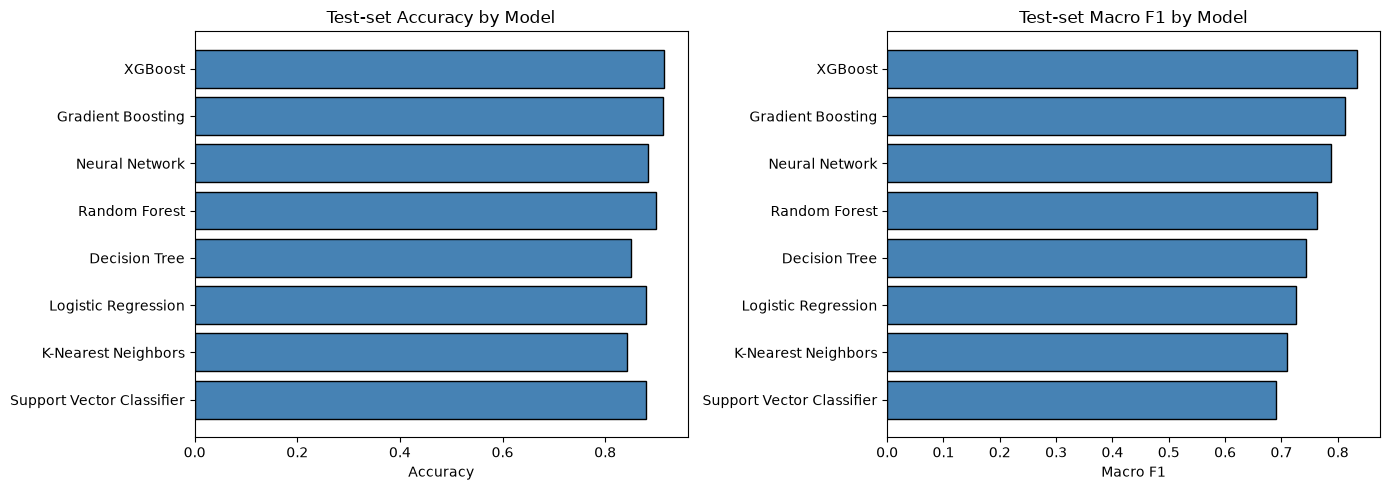

In [9]:
plot_order = eval_matrix_df.sort_values('F1 (macro)')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(plot_order['Model'], plot_order['Accuracy'], color='steelblue', edgecolor='black')
axes[0].set_xlabel('Accuracy')
axes[0].set_title('Test-set Accuracy by Model')

axes[1].barh(plot_order['Model'], plot_order['F1 (macro)'], color='steelblue', edgecolor='black')
axes[1].set_xlabel('Macro F1')
axes[1].set_title('Test-set Macro F1 by Model')

plt.tight_layout()
plt.show()

## Cross-Validation

Five-fold stratified cross-validation is used to get a more reliable estimate of generalisation. Macro F1 is used as the scoring criterion here, consistent with the primary evaluation metric and the hyperparameter tuning below, rather than accuracy, since accuracy alone would understate instability on the minority typology classes. Stratification ensures each fold maintains the same class proportions as the full dataset.

In [10]:
cv_results = []
cv_f1_mean, cv_f1_std = [], []  # retained separately (as floats) for the CV plot below
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor_clf), ('model', clone(model))])
    # y_train_clf is stratified by cross_val_score's default StratifiedKFold when
    # the estimator is a classifier, keeping class proportions consistent across
    # folds despite the imbalance between typology classes. Restricted to the
    # training fold only, so the held-out test set stays untouched here too.
    # macro F1 (not accuracy) to stay consistent with the primary metric and tuning.
    scores = cross_val_score(pipe, X_train_clf, y_train_clf, cv=5, scoring='f1_macro')
    cv_f1_mean.append(scores.mean())
    cv_f1_std.append(scores.std())
    cv_results.append({
        'Model':      name,
        'CV F1 mean': f'{scores.mean():.4f}',
        'CV F1 std':  f'+/- {scores.std():.4f}',
    })

cv_results_df = pd.DataFrame(cv_results)
cv_results_df


,Model,CV F1 mean,CV F1 std
0,Logistic Regression,0.6656,+/- 0.0216
1,Decision Tree,0.7416,+/- 0.0092
2,Random Forest,0.7799,+/- 0.0230
3,Gradient Boosting,0.7920,+/- 0.0339
4,XGBoost,0.7996,+/- 0.0207
5,Support Vector Classifier,0.6509,+/- 0.0151
6,K-Nearest Neighbors,0.6775,+/- 0.0066
7,Neural Network,0.7638,+/- 0.0294


The mean $\pm$ standard deviation macro F1 from the cross-validation above is plotted below, to compare model stability across folds visually rather than only from the table.

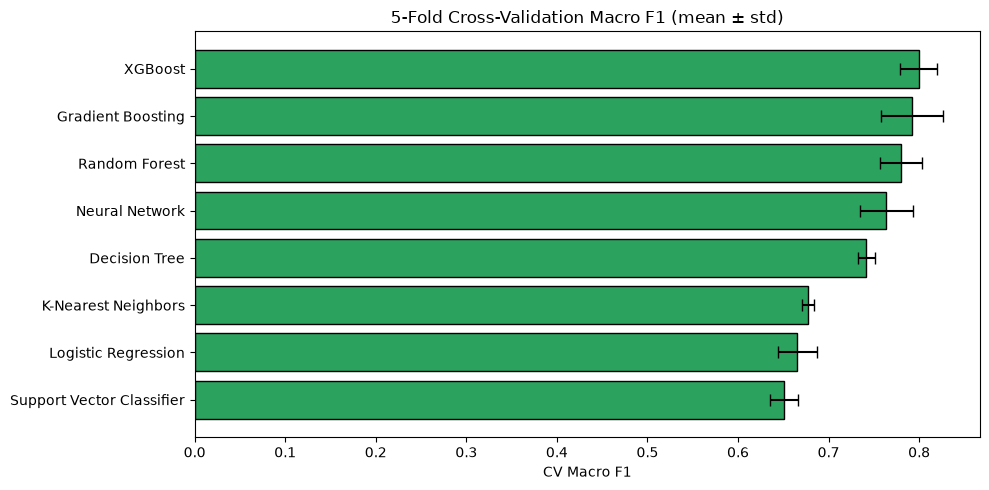

In [11]:
order       = np.argsort(cv_f1_mean)
model_names = list(models.keys())

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh([model_names[i] for i in order],
        [cv_f1_mean[i] for i in order],
        xerr=[cv_f1_std[i] for i in order],
        color='#2ca25f', edgecolor='black', capsize=4)
ax.set_xlabel('CV Macro F1')
ax.set_title('5-Fold Cross-Validation Macro F1 (mean \u00b1 std)')
plt.tight_layout()
plt.show()

## Confusion Matrices

The matrices below reveal where each model misclassifies houses. Systematic confusion between adjacent categories (Multi-story and 1.5-story in particular) is informative about the separability of the typology classes.

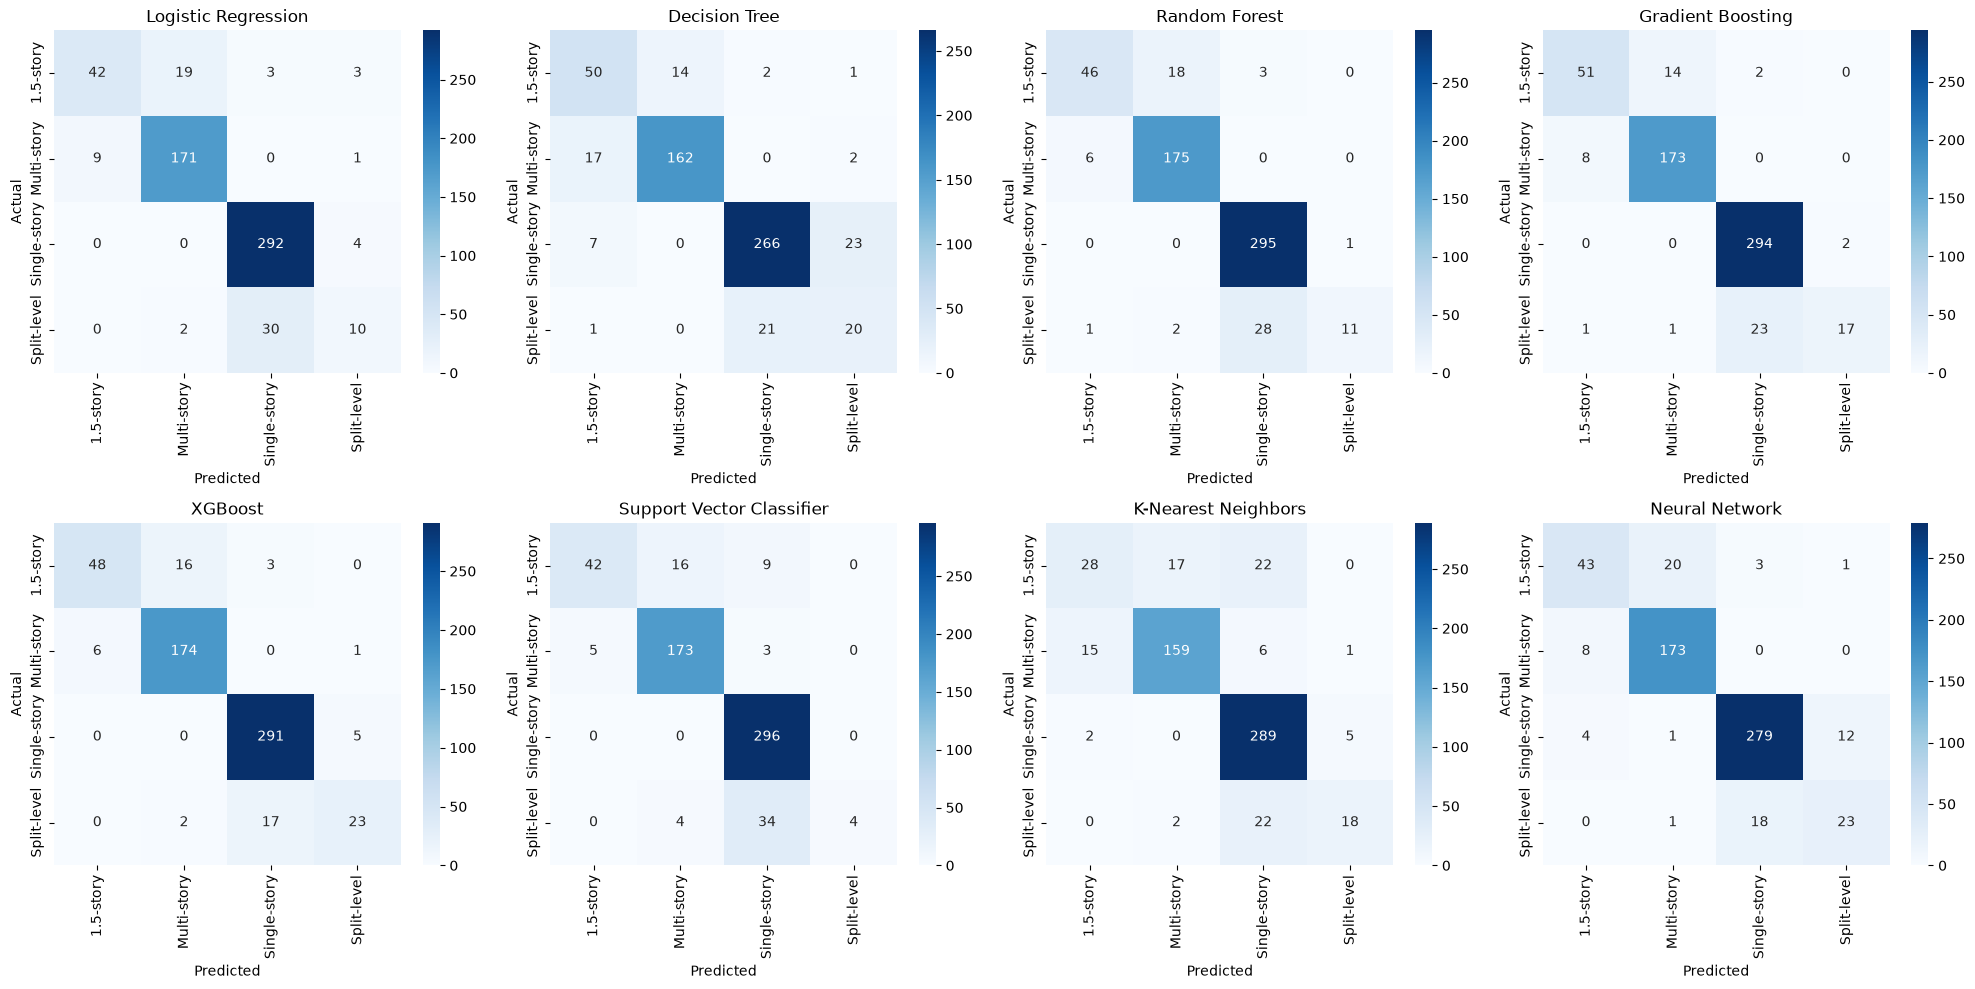

In [12]:
int_labels = sorted(y_clf.unique())   # [0, 1, 2, 3]
n_models   = len(trained_models)
n_cols     = 4
n_rows     = (n_models + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))
axes = axes.ravel()

for i, (name, y_pred) in enumerate(trained_models.items()):
    cm = confusion_matrix(y_test_clf, y_pred, labels=int_labels)
    sns.heatmap(cm, annot=True, fmt='d', ax=axes[i],
                xticklabels=class_labels, yticklabels=class_labels, cmap='Blues')
    axes[i].set_title(name)
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

### XGBoost Confusion Matrix (Default Hyperparameters)

XGBoost is isolated from the grid above and shown at a larger size, since it is the strongest classifier overall (Table above) and its confusion matrix is the one discussed in the results write-up.

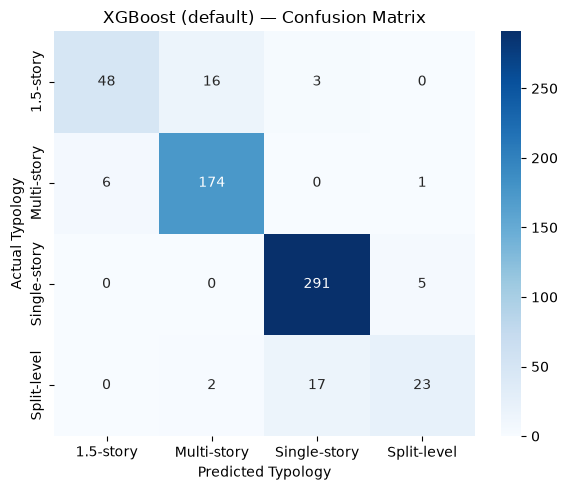

In [13]:
cm_xgb = confusion_matrix(y_test_clf, trained_models['XGBoost'], labels=int_labels)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_xgb, annot=True, fmt='d', ax=ax,
            xticklabels=class_labels, yticklabels=class_labels, cmap='Blues')
ax.set_title('XGBoost (default) \u2014 Confusion Matrix')
ax.set_xlabel('Predicted Typology')
ax.set_ylabel('Actual Typology')
plt.tight_layout()
plt.show()

## Per-class Performance

In [14]:
for name, y_pred in trained_models.items():
    print(f'=== {name} ===')
    print(classification_report(y_test_clf, y_pred,
                                target_names=class_labels, zero_division=0))

=== Logistic Regression ===
              precision    recall  f1-score   support

   1.5-story       0.82      0.63      0.71        67
 Multi-story       0.89      0.94      0.92       181
Single-story       0.90      0.99      0.94       296
 Split-level       0.56      0.24      0.33        42

    accuracy                           0.88       586
   macro avg       0.79      0.70      0.73       586
weighted avg       0.86      0.88      0.86       586

=== Decision Tree ===
              precision    recall  f1-score   support

   1.5-story       0.67      0.75      0.70        67
 Multi-story       0.92      0.90      0.91       181
Single-story       0.92      0.90      0.91       296
 Split-level       0.43      0.48      0.45        42

    accuracy                           0.85       586
   macro avg       0.74      0.75      0.74       586
weighted avg       0.86      0.85      0.85       586

=== Random Forest ===
              precision    recall  f1-score   support

   

## Hyperparameter Tuning

The four best-performing classifiers are tuned using cross-validated search, with macro F1 as the scoring criterion to weight all four classes equally. Random Forest and XGBoost use a randomised search; Gradient Boosting and SVC use an exhaustive grid search.

In [15]:
param_grids = {
    'Random Forest': {
        'model__n_estimators':      [50, 100, 200],
        'model__max_depth':         [None, 10, 20],
        'model__min_samples_split': [2, 5, 10],
    },
    'Gradient Boosting': {
        'model__n_estimators':  [50, 100, 200],
        'model__learning_rate': [0.01, 0.1, 0.2],
        'model__max_depth':     [3, 5, 7],
    },
    'XGBoost': {
        'model__n_estimators':  [50, 100, 200],
        'model__learning_rate': uniform(0.01, 0.3),
        'model__max_depth':     [3, 5, 7],
    },
    'Support Vector Classifier': {
        'model__kernel': ['linear', 'rbf'],
        'model__C':      [0.1, 1, 10],
        'model__gamma':  ['scale', 'auto'],
    },
}

## Model Selection for Tuning

Based on the initial comparison, the four best-performing classifiers are carried forward for hyperparameter search; the remaining models are not tuned further given their comparatively weaker baseline performance.

In [16]:
tune_models = {
    'Random Forest':             RandomForestClassifier(random_state=42),
    'Gradient Boosting':         GradientBoostingClassifier(random_state=42),
    'XGBoost':                   XGBClassifier(random_state=42,
                                               eval_metric='mlogloss', verbosity=0),
    'Support Vector Classifier': SVC(random_state=42),
}
best_models = {}

Each selected model is tuned in turn, using randomised search for Random Forest and XGBoost given their larger parameter spaces, and exhaustive grid search for Gradient Boosting and the Support Vector Classifier.

In [17]:
for name, model in tune_models.items():
    print(f'Tuning {name}...')
    pipe = Pipeline(steps=[('preprocessor', preprocessor_clf), ('model', model)])

    # RandomizedSearchCV samples a fixed number of parameter combinations
    # (n_iter=10) rather than the full grid, which is preferable for Random
    # Forest and XGBoost given their larger parameter spaces here.
    if name in ['Random Forest', 'XGBoost']:
        search = RandomizedSearchCV(
            pipe, param_distributions=param_grids[name],
            n_iter=10, cv=5, scoring='f1_macro',
            n_jobs=-1, random_state=42,
        )
    else:
        search = GridSearchCV(
            pipe, param_grid=param_grids[name],
            cv=5, scoring='f1_macro', n_jobs=-1,
        )

    search.fit(X_train_clf, y_train_clf)
    best_models[name] = search.best_estimator_
    print(f'  Best params      : {search.best_params_}')
    print(f'  Best CV F1 (mac) : {search.best_score_:.4f}')
    print()

Tuning Random Forest...
  Best params      : {'model__n_estimators': 50, 'model__min_samples_split': 5, 'model__max_depth': 20}
  Best CV F1 (mac) : 0.7725

Tuning Gradient Boosting...
  Best params      : {'model__learning_rate': 0.2, 'model__max_depth': 3, 'model__n_estimators': 100}
  Best CV F1 (mac) : 0.8058

Tuning XGBoost...
  Best params      : {'model__learning_rate': np.float64(0.13958350559263474), 'model__max_depth': 3, 'model__n_estimators': 200}
  Best CV F1 (mac) : 0.8082

Tuning Support Vector Classifier...
  Best params      : {'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
  Best CV F1 (mac) : 0.7785



## Results after Tuning

In [18]:
eval_matrix = []
for name, model in best_models.items():
    y_pred = model.predict(X_test_clf)
    eval_matrix.append(evaluation_matrix(name, y_test_clf, y_pred))

eval_matrix_df = pd.DataFrame(eval_matrix)
eval_matrix_df

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,Random Forest,0.8993,0.8933,0.7349,0.7698
1,Gradient Boosting,0.9096,0.8843,0.7769,0.8113
2,XGBoost,0.9181,0.8839,0.8055,0.8366
3,Support Vector Classifier,0.8959,0.8458,0.7650,0.7959


Confusion matrices for the tuned models are plotted to examine whether hyperparameter tuning altered the pattern of misclassification observed previously.

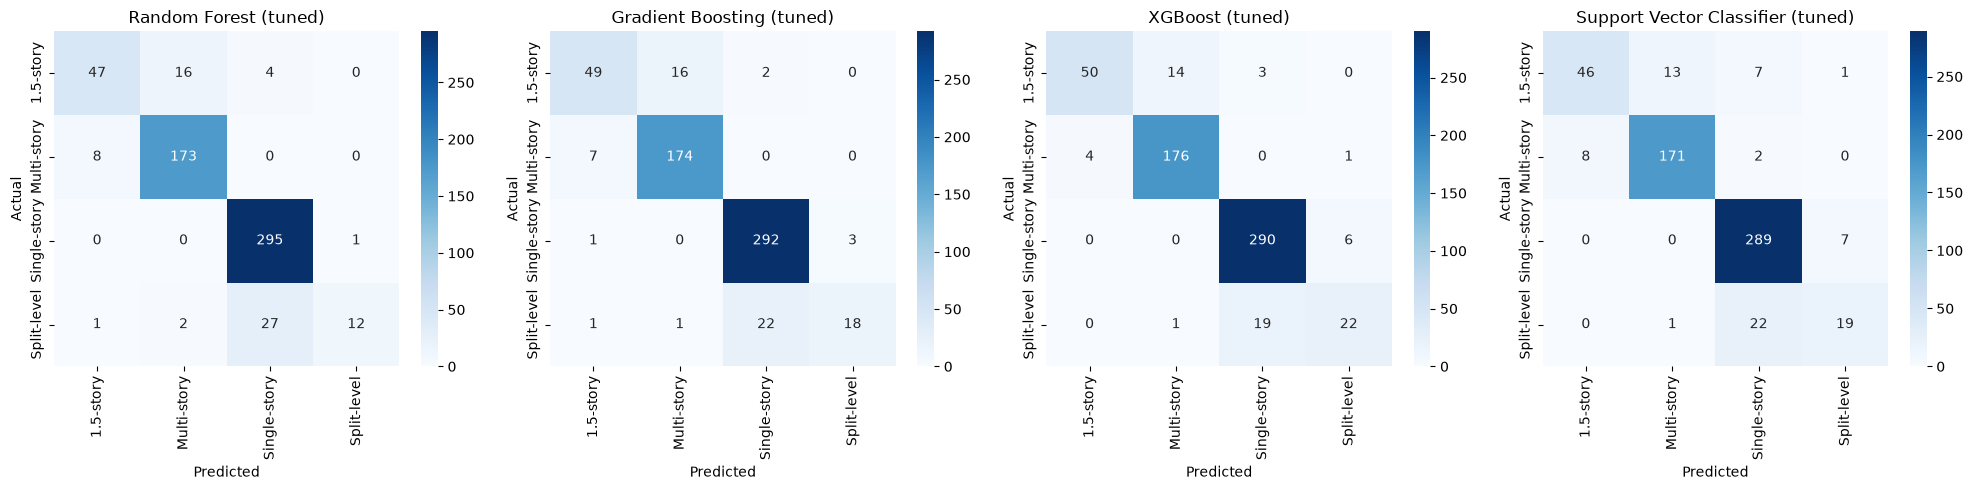

In [19]:
int_labels = sorted(y_clf.unique())
fig, axes  = plt.subplots(1, len(best_models), figsize=(5 * len(best_models), 5))
if len(best_models) == 1:
    axes = [axes]

for i, (name, model) in enumerate(best_models.items()):
    y_pred = model.predict(X_test_clf)
    cm = confusion_matrix(y_test_clf, y_pred, labels=int_labels)
    sns.heatmap(cm, annot=True, fmt='d', ax=axes[i],
                xticklabels=class_labels, yticklabels=class_labels, cmap='Blues')
    axes[i].set_title(f'{name} (tuned)')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## Feature Importance (Tuned Random Forest and XGBoost)

Mean-decrease-in-impurity feature importance is extracted from the two tuned tree ensembles to check which of the 30 geometric predictors they actually rely on for the typology task. As with the regression models, this reflects predictive contribution within these specific fitted models, not a causal effect.

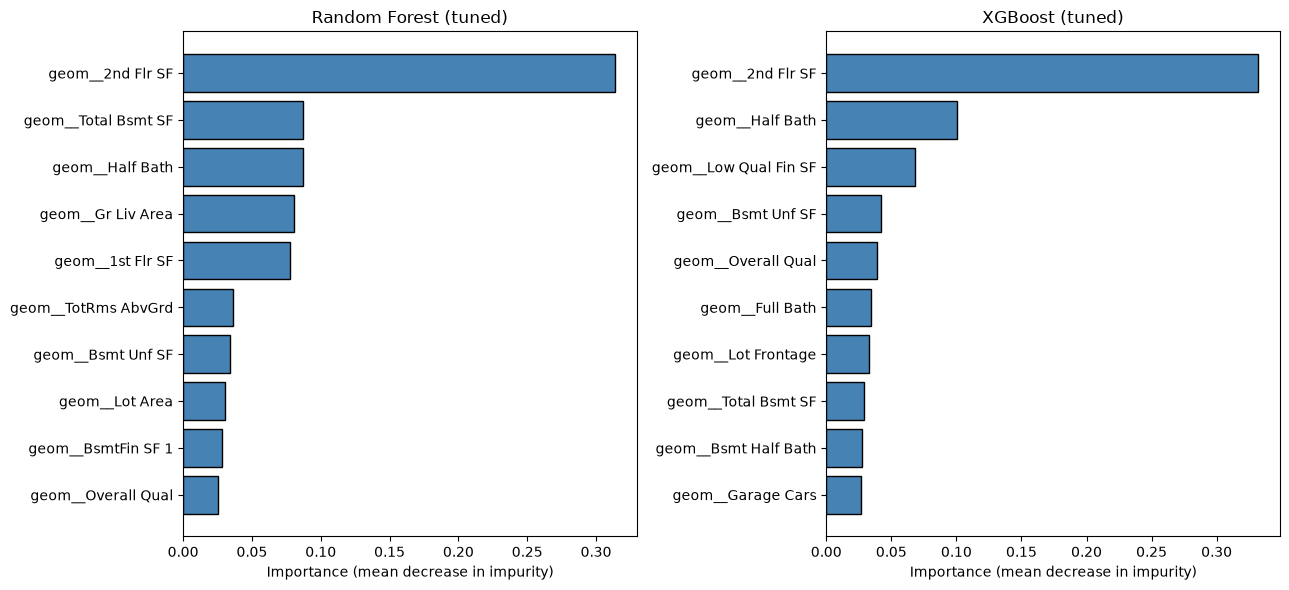

Random Forest -- top 3 features:
  geom__2nd Flr SF               0.3139
  geom__Total Bsmt SF            0.0874
  geom__Half Bath                0.0868

XGBoost -- top 3 features:
  geom__2nd Flr SF               0.3321
  geom__Half Bath                0.1005
  geom__Low Qual Fin SF          0.0680



In [20]:
fi_models = {name: best_models[name] for name in ['Random Forest', 'XGBoost']}

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, (name, pipe) in zip(axes, fi_models.items()):
    feat_names  = pipe.named_steps['preprocessor'].get_feature_names_out()
    importances = pipe.named_steps['model'].feature_importances_
    top_idx     = np.argsort(importances)[-10:]
    ax.barh(range(len(top_idx)), importances[top_idx], color='steelblue', edgecolor='black')
    ax.set_yticks(range(len(top_idx)))
    ax.set_yticklabels([feat_names[i] for i in top_idx])
    ax.set_xlabel('Importance (mean decrease in impurity)')
    ax.set_title(f'{name} (tuned)')
plt.tight_layout()
plt.show()

for name, pipe in fi_models.items():
    feat_names  = pipe.named_steps['preprocessor'].get_feature_names_out()
    importances = pipe.named_steps['model'].feature_importances_
    top3 = np.argsort(importances)[::-1][:3]
    print(f'{name} -- top 3 features:')
    for i in top3:
        print(f'  {feat_names[i]:30s} {importances[i]:.4f}')
    print()


## Results & Discussion

XGBoost is the strongest classifier both before tuning (accuracy 0.915, macro F1 0.833) and after (accuracy 0.918, macro F1 0.837), with Gradient Boosting the closest competitor throughout. Random Forest and XGBoost both reach a macro precision above 0.88, but XGBoost's macro recall (0.802–0.806) is consistently 3–8 points higher, which macro F1 rewards directly - this is the main reason it ranks first despite Random Forest and the SVC both posting higher precision at various points.

The gap between accuracy and macro F1 is largest for the Support Vector Classifier before tuning (accuracy 0.879, macro F1 0.691) and shrinks sharply after (accuracy 0.896, macro F1 0.796). The untuned SVC's default `C` and `gamma` produce a conservative decision boundary that rarely predicts Split-level (only 4 of 42 correctly, from the earlier confusion matrix), which inflates precision on the rare cases it does predict while depressing recall; a wider margin parameter (`C=10`, found by the search) corrects most of this. This is the clearest example in either notebook of a model whose default hyperparameters were not suited to the class distribution.

Across every model and both tuning stages, Split-level is the class with the lowest recall - even tuned XGBoost recovers only about half of its true instances (22 of 42), confusing most of the remainder with Single-story or Multi-story. Since Split-level and 1.5-story homes have partial floors at intermediate configurations, the 30 aggregate geometric features used here (total areas, room counts) do not fully capture the vertical arrangement that would separate these forms from a full two-storey layout. This is a structural limit on the achievable macro F1 for this feature set rather than a model selection problem, since it appears consistently across linear, tree-based and margin-based classifiers alike.